# Organ Ablation: Organ-Sweep Variants

This notebook analyzes the organ-augmentation variants produced by
`scripts/run_organ_sweep.sh` and evaluated with `scripts/eval_organ_sweep.sh`.

It loads frame-level predictions, attaches ground-truth labels, and reports
confusion counts and basic metrics per target (C1/C2/C3/CVS).


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

ROOT_DIR = Path("..").resolve()
RUNS_DIR = ROOT_DIR / "runs" / "organ_sweep"
DATASET_ROOT = ROOT_DIR / "data" / "CVS_Challenge_SAGES_v1"
FRAMES_ROOT = ROOT_DIR / "data" / "frames"


## Load predictions and ground truth


In [2]:
def _parse01(x):
    if x is None:
        return np.nan
    if isinstance(x, bool):
        return 1 if x else 0
    if isinstance(x, (int, float, np.integer, np.floating)):
        try:
            return 1 if int(x) == 1 else 0
        except Exception:
            return np.nan
    s = str(x).strip().lower()
    if s in {"1", "true", "t", "yes", "y"}:
        return 1
    if s in {"0", "false", "f", "no", "n"}:
        return 0
    return np.nan


def _derive_sample_key(split: str, video_id: str, frame_id: int) -> str:
    return f"{split}/{video_id}/frame_{frame_id:06d}"


def _load_record(run_dir: Path) -> dict:
    path = run_dir / "record.json"
    if not path.exists():
        return {}
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except Exception:
        return {}


def _load_gt_frame_majority(video_id: str, split: str) -> pd.DataFrame:
    frame_csv = DATASET_ROOT / split / "labels" / str(video_id) / "frame.csv"
    if not frame_csv.exists():
        return pd.DataFrame()
    df = pd.read_csv(frame_csv)
    if "frame_id" not in df.columns:
        return pd.DataFrame()
    out = pd.DataFrame({"frame_id": pd.to_numeric(df["frame_id"], errors="coerce")})
    out = out.dropna(subset=["frame_id"]).copy()
    out["frame_id"] = out["frame_id"].astype(int)
    for crit in ("c1", "c2", "c3"):
        cols = [f"{crit}_rater1", f"{crit}_rater2", f"{crit}_rater3"]
        if not set(cols).issubset(set(df.columns)):
            return pd.DataFrame()
        v = df.loc[out.index, cols].astype(int).sum(axis=1)
        out[f"gt_{crit}"] = (v >= 2).astype(int)
    out["gt_cvs"] = (out["gt_c1"] & out["gt_c2"] & out["gt_c3"]).astype(int)
    return out.set_index("frame_id", drop=False)


def load_predictions() -> pd.DataFrame:
    if not RUNS_DIR.exists():
        raise SystemExit(f"Missing runs directory: {RUNS_DIR}")

    run_dirs = sorted(
        [p for p in RUNS_DIR.iterdir() if p.is_dir() and (p / "pred.jsonl").exists()]
    )
    if not run_dirs:
        raise SystemExit(f"No run folders with pred.jsonl under {RUNS_DIR}")

    rows = []
    for run_dir in run_dirs:
        pred_path = run_dir / "pred.jsonl"
        record = _load_record(run_dir)
        organ_variant = record.get("organ_variant") or run_dir.name
        method = record.get("method") or "unknown"
        protocol = record.get("protocol") or "unknown"

        with pred_path.open("r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                obj = json.loads(line)
                vid = obj.get("id")
                fid = obj.get("frame_id")
                split = obj.get("split") or "unknown"
                if vid is None or fid is None:
                    continue
                try:
                    fid = int(fid)
                except Exception:
                    continue

                sample_key = _derive_sample_key(str(split), str(vid), fid)
                rows.append(
                    {
                        "sample_key": sample_key,
                        "split": str(split),
                        "video_id": str(vid),
                        "frame_id": fid,
                        "image_path": (
                            FRAMES_ROOT / str(split) / str(vid) / f"frame_{fid:06d}.jpg"
                        ).as_posix(),
                        "run_name": run_dir.name,
                        "organ_variant": organ_variant,
                        "organ_injection": record.get("organ_injection"),
                        "organ_source": record.get("organ_source"),
                        "organ_top_k": record.get("organ_top_k"),
                        "organ_threshold": record.get("organ_threshold"),
                        "organ_include_union": record.get("organ_include_union"),
                        "method": str(method),
                        "protocol": str(protocol),
                        "pred_C1": _parse01(obj.get("c1")),
                        "pred_C2": _parse01(obj.get("c2")),
                        "pred_C3": _parse01(obj.get("c3")),
                        "pred_CVS": _parse01(obj.get("cvs_final")),
                    }
                )

    return pd.DataFrame(rows)


pred_df = load_predictions()
if pred_df.empty:
    raise SystemExit("No usable predictions loaded.")

# Attach GT

gt_rows = []
for (split, vid), d in pred_df.groupby(["split", "video_id"], sort=False):
    if split == "unknown":
        continue
    gt = _load_gt_frame_majority(str(vid), str(split))
    if gt.empty:
        continue
    frame_ids = d["frame_id"].astype(int).unique().tolist()
    sub = gt.loc[gt.index.intersection(frame_ids)][
        ["frame_id", "gt_c1", "gt_c2", "gt_c3", "gt_cvs"]
    ].copy()
    sub["split"] = str(split)
    sub["video_id"] = str(vid)
    gt_rows.append(sub)

gt_df = pd.concat(gt_rows, ignore_index=True) if gt_rows else pd.DataFrame()

pred_df = pred_df.merge(gt_df, on=["split", "video_id", "frame_id"], how="left")

# Long format
long_rows = []
for _, r in pred_df.iterrows():
    for target, pred_col, gt_col in [
        ("C1", "pred_C1", "gt_c1"),
        ("C2", "pred_C2", "gt_c2"),
        ("C3", "pred_C3", "gt_c3"),
        ("CVS", "pred_CVS", "gt_cvs"),
    ]:
        y_pred = r.get(pred_col)
        y_true = r.get(gt_col)
        if pd.isna(y_pred) or pd.isna(y_true):
            continue
        y_pred = int(y_pred)
        y_true = int(y_true)
        long_rows.append(
            {
                "sample_key": r["sample_key"],
                "split": r["split"],
                "run_name": r["run_name"],
                "organ_variant": r["organ_variant"],
                "organ_injection": r.get("organ_injection"),
                "organ_source": r.get("organ_source"),
                "organ_top_k": r.get("organ_top_k"),
                "organ_threshold": r.get("organ_threshold"),
                "organ_include_union": r.get("organ_include_union"),
                "method": r.get("method"),
                "protocol": r.get("protocol"),
                "target": target,
                "y_true": y_true,
                "y_pred": y_pred,
                "correct": bool(y_true == y_pred),
            }
        )

df_long = pd.DataFrame(long_rows)

# Dedupe by sample/variant/target to avoid inflation.
if not df_long.empty:
    dup_cols = ["sample_key", "organ_variant", "target"]
    dup_mask = df_long.duplicated(dup_cols, keep=False)
    if dup_mask.any():
        dup_count = int(dup_mask.sum())
        print(f"Found {dup_count} duplicate rows; keeping last per {dup_cols}")
        df_long = df_long.drop_duplicates(dup_cols, keep="last").reset_index(drop=True)

print("organ_variants:", sorted(df_long["organ_variant"].unique().tolist()))
print("targets:", sorted(df_long["target"].unique().tolist()))

df_long.head()


organ_variants: ['orgbbox_text_bbox_topk', 'orgseg_overlay_contour', 'orgseg_overlay_fill', 'orgseg_text_centroid_topk', 'orgseg_text_stats_topk']
targets: ['C1', 'C2', 'C3']


,sample_key,split,run_name,organ_variant,organ_injection,organ_source,organ_top_k,organ_threshold,organ_include_union,method,protocol,target,y_true,y_pred,correct
0,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,sequential_inductive_gpt-4.1-mini_train_dev5__...,orgbbox_text_bbox_topk,text_bbox_topk,overlay_bbox,3,0.5,1,sequential_inductive,obs_then_decide,C1,0,0,True
1,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,sequential_inductive_gpt-4.1-mini_train_dev5__...,orgbbox_text_bbox_topk,text_bbox_topk,overlay_bbox,3,0.5,1,sequential_inductive,obs_then_decide,C2,0,0,True
2,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,sequential_inductive_gpt-4.1-mini_train_dev5__...,orgbbox_text_bbox_topk,text_bbox_topk,overlay_bbox,3,0.5,1,sequential_inductive,obs_then_decide,C3,0,0,True
3,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,sequential_inductive_gpt-4.1-mini_train_dev5__...,orgbbox_text_bbox_topk,text_bbox_topk,overlay_bbox,3,0.5,1,sequential_inductive,obs_then_decide,C1,1,0,False
4,train/925421af-7c79-4f7c-b573-48732718ebd1/fra...,train,sequential_inductive_gpt-4.1-mini_train_dev5__...,orgbbox_text_bbox_topk,text_bbox_topk,overlay_bbox,3,0.5,1,sequential_inductive,obs_then_decide,C2,1,0,False


## Coverage by organ variant


In [3]:
coverage = (
    df_long[["sample_key", "organ_variant", "target"]]
    .drop_duplicates()
    .groupby(["organ_variant", "target"])
    .size()
    .reset_index(name="num_samples")
    .sort_values(["organ_variant", "target"])
)
coverage


,organ_variant,target,num_samples
0,orgbbox_text_bbox_topk,C1,90
1,orgbbox_text_bbox_topk,C2,90
2,orgbbox_text_bbox_topk,C3,90
3,orgseg_overlay_contour,C1,90
4,orgseg_overlay_contour,C2,90
5,orgseg_overlay_contour,C3,90
6,orgseg_overlay_fill,C1,90
7,orgseg_overlay_fill,C2,90
8,orgseg_overlay_fill,C3,90
9,orgseg_text_centroid_topk,C1,90


## Confusion counts and metrics by variant


In [4]:
def confusion_metrics(d: pd.DataFrame) -> dict:
    y_true = d["y_true"].astype(int)
    y_pred = d["y_pred"].astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    total = tp + tn + fp + fn
    acc = (tp + tn) / total if total else np.nan
    prec = tp / (tp + fp) if (tp + fp) else np.nan
    rec = tp / (tp + fn) if (tp + fn) else np.nan
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else np.nan
    return {
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "support": total,
        "acc": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
    }


rows = []
for (variant, target), d in df_long.groupby(["organ_variant", "target"], sort=False):
    m = confusion_metrics(d)
    rows.append({"organ_variant": variant, "target": target, **m})

metrics_df = pd.DataFrame(rows).sort_values(["organ_variant", "target"]).reset_index(drop=True)
metrics_df


,organ_variant,target,tp,tn,fp,fn,support,acc,precision,recall,f1
0,orgbbox_text_bbox_topk,C1,11,41,28,10,90,0.577778,0.282051,0.523810,0.366667
1,orgbbox_text_bbox_topk,C2,15,36,17,22,90,0.566667,0.468750,0.405405,0.434783
2,orgbbox_text_bbox_topk,C3,12,41,29,8,90,0.588889,0.292683,0.600000,0.393443
3,orgseg_overlay_contour,C1,17,42,27,4,90,0.655556,0.386364,0.809524,0.523077
4,orgseg_overlay_contour,C2,28,25,28,9,90,0.588889,0.500000,0.756757,0.602151
5,orgseg_overlay_contour,C3,17,34,36,3,90,0.566667,0.320755,0.850000,0.465753
6,orgseg_overlay_fill,C1,18,38,31,3,90,0.622222,0.367347,0.857143,0.514286
7,orgseg_overlay_fill,C2,26,21,32,11,90,0.522222,0.448276,0.702703,0.547368
8,orgseg_overlay_fill,C3,15,32,38,5,90,0.522222,0.283019,0.750000,0.410959
9,orgseg_text_centroid_topk,C1,7,52,17,14,90,0.655556,0.291667,0.333333,0.311111


## Summary table (macro/micro across C1-3)


In [5]:
def summarize_per_variant(metrics_df: pd.DataFrame) -> pd.DataFrame:
    crits = ["C1", "C2", "C3"]
    m = metrics_df[metrics_df["target"].isin(crits)].copy()

    def _micro_acc(g):
        TP = g["tp"].sum()
        TN = g["tn"].sum()
        FP = g["fp"].sum()
        FN = g["fn"].sum()
        denom = TP + TN + FP + FN
        return (TP + TN) / denom if denom > 0 else np.nan

    out = (
        m.groupby("organ_variant", sort=False)
         .apply(lambda g: pd.Series({
             "avg_recall": g["recall"].mean(),
             "avg_f1": g["f1"].mean(),
             "macro_accuracy": g["acc"].mean(),
             "micro_accuracy": _micro_acc(g),
             "C1_recall": float(g.loc[g["target"]=="C1","recall"].iloc[0]) if (g["target"]=="C1").any() else np.nan,
             "C2_recall": float(g.loc[g["target"]=="C2","recall"].iloc[0]) if (g["target"]=="C2").any() else np.nan,
             "C3_recall": float(g.loc[g["target"]=="C3","recall"].iloc[0]) if (g["target"]=="C3").any() else np.nan,
             "C1_f1": float(g.loc[g["target"]=="C1","f1"].iloc[0]) if (g["target"]=="C1").any() else np.nan,
             "C2_f1": float(g.loc[g["target"]=="C2","f1"].iloc[0]) if (g["target"]=="C2").any() else np.nan,
             "C3_f1": float(g.loc[g["target"]=="C3","f1"].iloc[0]) if (g["target"]=="C3").any() else np.nan,
         }))
         .reset_index()
    )
    cols = [
        "organ_variant",
        "avg_recall",
        "avg_f1",
        "micro_accuracy",
        "macro_accuracy",
        "C1_recall",
        "C2_recall",
        "C3_recall",
        "C1_f1",
        "C2_f1",
        "C3_f1",
    ]
    return out[cols].sort_values(["avg_f1", "avg_recall"], ascending=False).reset_index(drop=True)


summary_df = summarize_per_variant(metrics_df)
summary_df


,organ_variant,avg_recall,avg_f1,micro_accuracy,macro_accuracy,C1_recall,C2_recall,C3_recall,C1_f1,C2_f1,C3_f1
0,orgseg_overlay_contour,0.805427,0.530327,0.603704,0.603704,0.809524,0.756757,0.85,0.523077,0.602151,0.465753
1,orgseg_overlay_fill,0.769949,0.490871,0.555556,0.555556,0.857143,0.702703,0.75,0.514286,0.547368,0.410959
2,orgbbox_text_bbox_topk,0.509738,0.398297,0.577778,0.577778,0.523810,0.405405,0.60,0.366667,0.434783,0.393443
3,orgseg_text_stats_topk,0.400965,0.337874,0.566667,0.566667,0.428571,0.324324,0.45,0.339623,0.358209,0.315789
4,orgseg_text_centroid_topk,0.335886,0.329979,0.618519,0.618519,0.333333,0.324324,0.35,0.311111,0.380952,0.297872


## Plot: recall/precision/f1 by organ variant


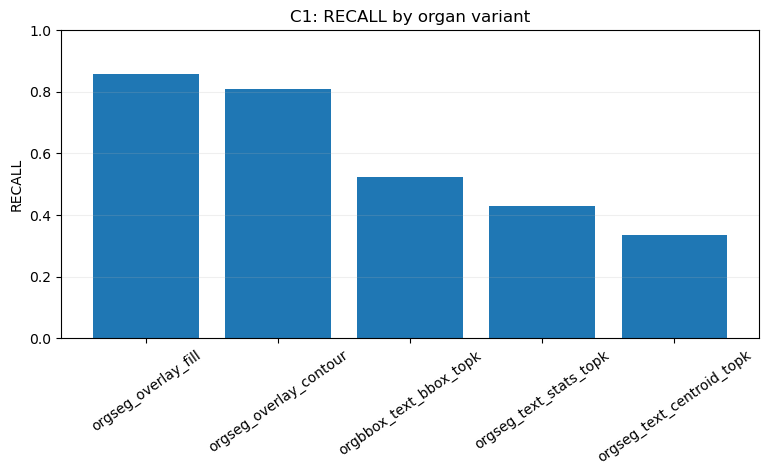

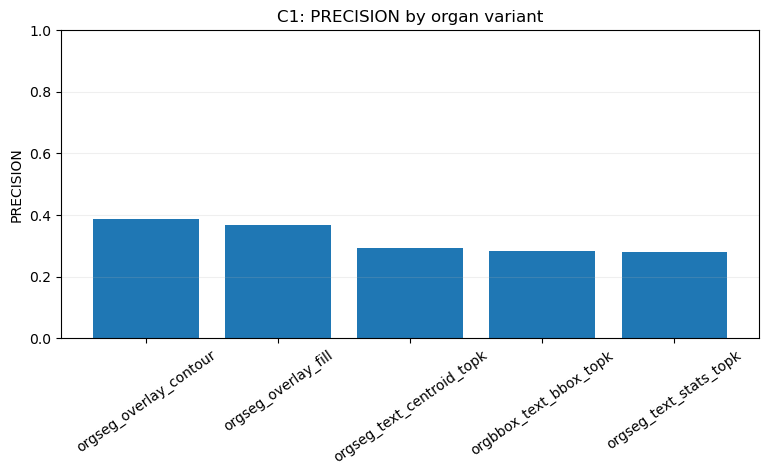

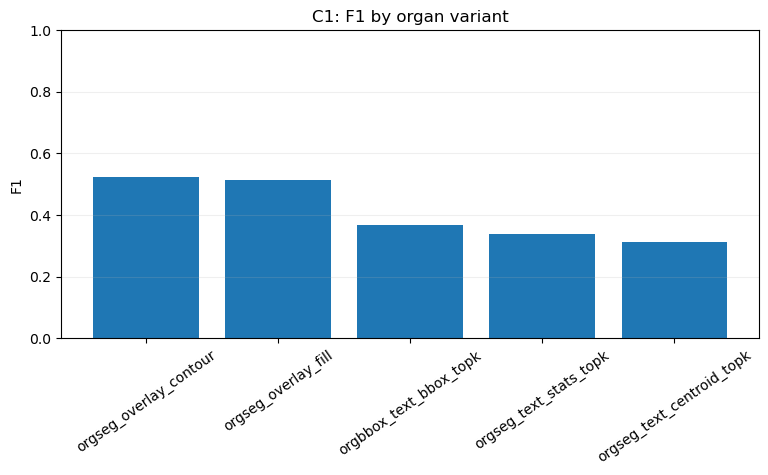

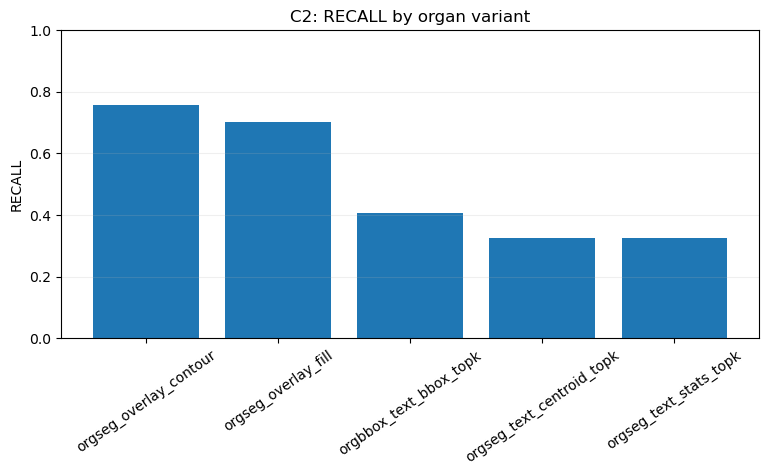

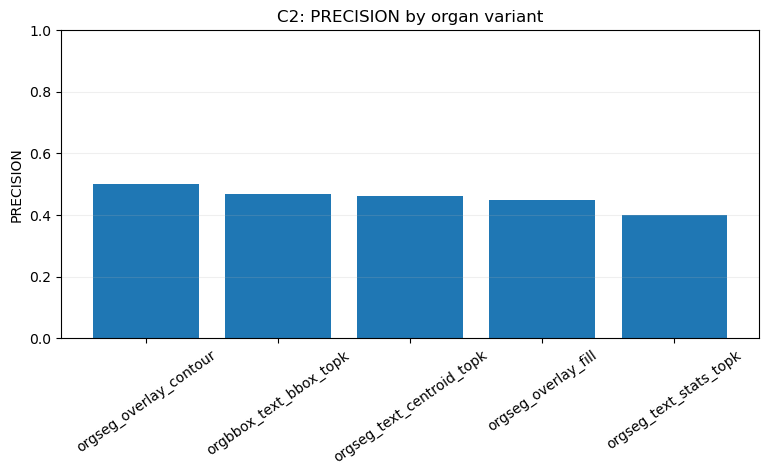

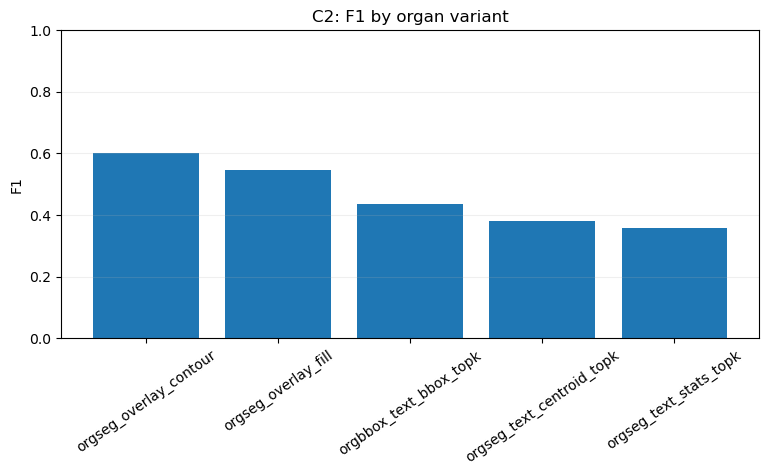

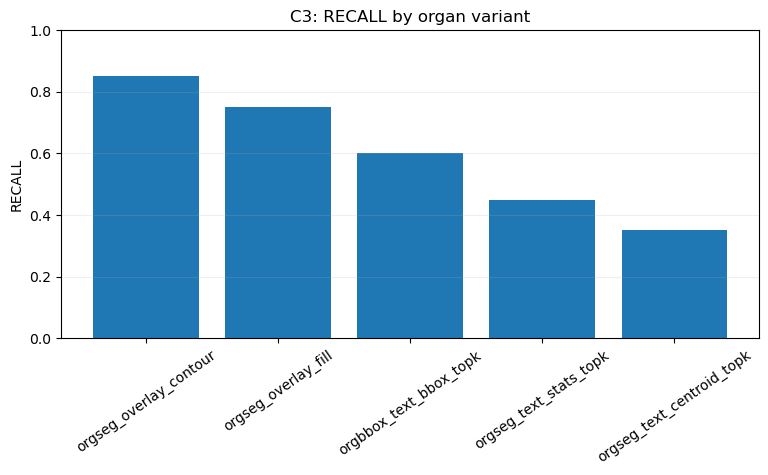

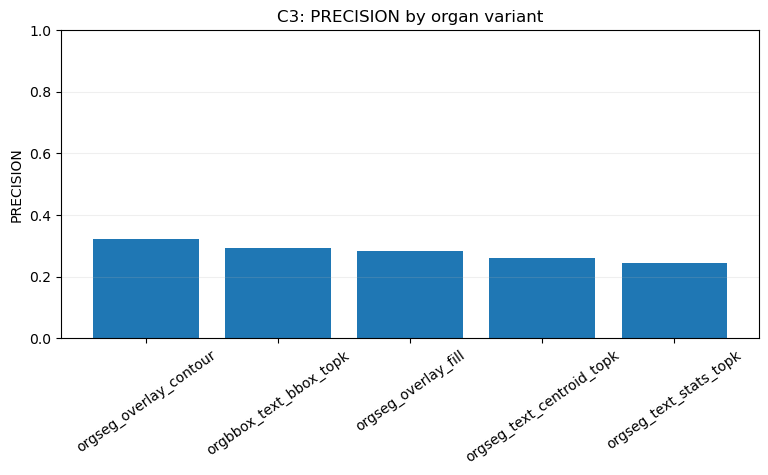

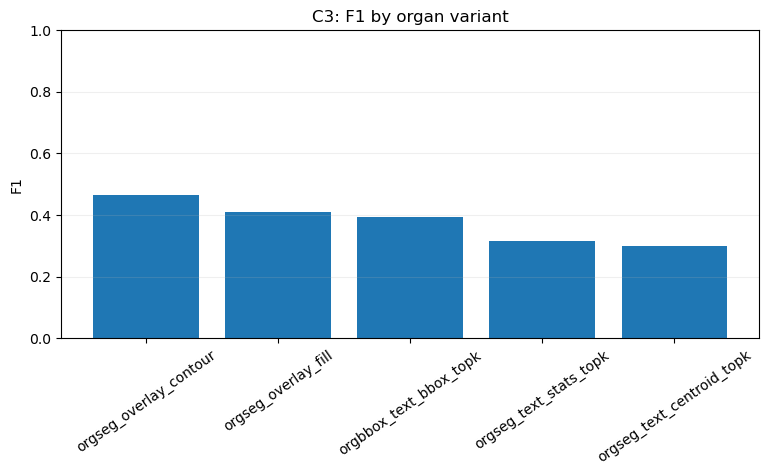

No data for target=CVS
No data for target=CVS
No data for target=CVS


In [6]:
import matplotlib.pyplot as plt


def plot_metric_by_variant(metrics_df: pd.DataFrame, target: str, metric: str):
    sub = metrics_df[metrics_df["target"] == target].copy()
    if sub.empty:
        print(f"No data for target={target}")
        return

    sub = sub.sort_values(metric, ascending=False)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(sub["organ_variant"], sub[metric])
    ax.set_title(f"{target}: {metric.upper()} by organ variant")
    ax.set_ylabel(metric.upper())
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.2)
    ax.tick_params(axis='x', rotation=35)
    plt.show()


for t in ["C1", "C2", "C3", "CVS"]:
    for metric in ["recall", "precision", "f1"]:
        plot_metric_by_variant(metrics_df, target=t, metric=metric)


## CVS errors (quick inspection)


In [7]:
# Show a few false positives / false negatives per organ variant for CVS.

cvs = df_long[df_long["target"] == "CVS"].copy()

fp = cvs[(cvs["y_true"] == 0) & (cvs["y_pred"] == 1)]
fn = cvs[(cvs["y_true"] == 1) & (cvs["y_pred"] == 0)]

fp_samples = (
    fp.groupby("organ_variant", group_keys=False)["sample_key"]
    .apply(lambda s: sorted(s.unique().tolist())[:5])
    .reset_index(name="false_positives")
)
fn_samples = (
    fn.groupby("organ_variant", group_keys=False)["sample_key"]
    .apply(lambda s: sorted(s.unique().tolist())[:5])
    .reset_index(name="false_negatives")
)

fp_samples.merge(fn_samples, on="organ_variant", how="outer").sort_values("organ_variant")


,false_positives,organ_variant,false_negatives
